Objetivo:
Comparar el desempeño de redes neuronales con:

Distinto número de capas ocultas

Aplicación de diferentes tasas de Dropout

Usando el dataset Fashion-MNIST para clasificación de imágenes.

Versión en Keras (Tensor Flow)

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.datasets import fashion_mnist
import time

In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
def build_model(num_layers=1, dropout_rate=0.0):
    model = Sequential([Flatten(input_shape=(28, 28))])
    for _ in range(num_layers):
        model.add(Dense(128, activation='relu'))
        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))
    model.add(Dense(10, activation='softmax'))
    return model

In [4]:
configuraciones = [
    {"layers": 1, "dropout": 0.0},
    {"layers": 2, "dropout": 0.2},
    {"layers": 3, "dropout": 0.3},
    {"layers": 2, "dropout": 0.5},
]

In [5]:
for cfg in configuraciones:
    print(f"\n🔧 Capas: {cfg['layers']} | Dropout: {cfg['dropout']}")
    model = build_model(cfg["layers"], cfg["dropout"])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    start = time.time()
    model.fit(x_train, y_train, epochs=3, batch_size=128, verbose=0)
    duration = time.time() - start

    _, acc = model.evaluate(x_test, y_test, verbose=0)
    print(f"⏱ Tiempo: {duration:.2f}s | 🎯 Accuracy: {acc:.4f}")


🔧 Capas: 1 | Dropout: 0.0


/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


⏱ Tiempo: 11.96s | 🎯 Accuracy: 0.8603

🔧 Capas: 2 | Dropout: 0.2
⏱ Tiempo: 14.19s | 🎯 Accuracy: 0.8623

🔧 Capas: 3 | Dropout: 0.3
⏱ Tiempo: 16.44s | 🎯 Accuracy: 0.8467

🔧 Capas: 2 | Dropout: 0.5
⏱ Tiempo: 15.79s | 🎯 Accuracy: 0.8452


Versión en Pytorch

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import time

In [7]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [8]:
transform = transforms.ToTensor()
trainset = torchvision.datasets.FashionMNIST('./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.FashionMNIST('./data', train=False, download=True, transform=transform)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 208kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.89MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 5.69MB/s]


In [9]:
trainloader = DataLoader(trainset, batch_size=128, shuffle=True)
testloader = DataLoader(testset, batch_size=1000)

In [10]:
class MLP(nn.Module):
    def __init__(self, num_layers=1, dropout_rate=0.0):
        super().__init__()
        self.flatten = nn.Flatten()
        self.hidden = nn.ModuleList()
        input_dim = 28*28
        for _ in range(num_layers):
            self.hidden.append(nn.Linear(input_dim, 128))
            input_dim = 128
        self.dropout = nn.Dropout(dropout_rate)
        self.output = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        for layer in self.hidden:
            x = F.relu(layer(x))
            x = self.dropout(x)
        return self.output(x)

In [11]:
configuraciones = [
    {"layers": 1, "dropout": 0.0},
    {"layers": 2, "dropout": 0.2},
    {"layers": 3, "dropout": 0.3},
    {"layers": 2, "dropout": 0.5},
]

In [12]:
criterion = nn.CrossEntropyLoss()

In [13]:
for cfg in configuraciones:
    print(f"\n🔧 Capas: {cfg['layers']} | Dropout: {cfg['dropout']}")
    model = MLP(cfg["layers"], cfg["dropout"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    start = time.time()
    model.train()
    for epoch in range(3):
        for inputs, targets in trainloader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
    duration = time.time() - start

    model.eval()
    correct = total = 0
    with torch.no_grad():
        for inputs, targets in testloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()
    acc = correct / total
    print(f"⏱ Tiempo: {duration:.2f}s | 🎯 Accuracy: {acc:.4f}")


🔧 Capas: 1 | Dropout: 0.0
⏱ Tiempo: 27.22s | 🎯 Accuracy: 0.8585

🔧 Capas: 2 | Dropout: 0.2
⏱ Tiempo: 28.64s | 🎯 Accuracy: 0.8608

🔧 Capas: 3 | Dropout: 0.3
⏱ Tiempo: 29.46s | 🎯 Accuracy: 0.8539

🔧 Capas: 2 | Dropout: 0.5
⏱ Tiempo: 27.60s | 🎯 Accuracy: 0.8471


Elaborar una tabla comparativa como la siguiente:

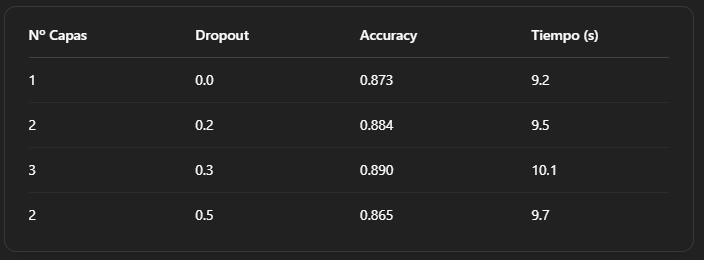

Extras (opcional):

* Te puedo incluir el ejercicio en formato .ipynb listo para Google Colab.
* Puedo agregar una autoevaluación práctica o preguntas para reflexionar sobre el impacto del número de capas y el dropout.
* También puedo agregar visualizaciones comparativas como gráficas de barras o líneas.

Repetir el experimento variando learning_rate: 0.001, 0.01, 0.1.

In [16]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Conv2D, MaxPooling2D # Import Conv2D and MaxPooling2D here

In [17]:
lrs = [0.001, 0.01, 0.1]
for lr in lrs:
    print(f"\n🔍 Learning rate: {lr}")
    model = Sequential([
        Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
        MaxPooling2D(2,2),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])

    optimizer = Adam(learning_rate=lr)
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    model.fit(x_train, y_train, epochs=3, batch_size=128, verbose=0)
    loss, acc = model.evaluate(x_test, y_test, verbose=0)
    print(f"🎯 Accuracy: {acc:.4f}")


🔍 Learning rate: 0.001


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


🎯 Accuracy: 0.8930

🔍 Learning rate: 0.01
🎯 Accuracy: 0.8986

🔍 Learning rate: 0.1
🎯 Accuracy: 0.8002


Bonus: Dropout y Regularización
Agregar una capa de Dropout(0.5) después de la capa densa. Comparar con/ sin dropout.